In [1]:
import os
import pandas as pd
from torchvision.io import decode_image
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor
from PIL import Image
import torch.nn.functional as F

In [3]:
class ImageDatasetFromFolders(Dataset):
    def __init__(self, path, transform=ToTensor):
        self.path = path
        self.class_names = sorted(os.listdir(self.path))
        self.transform = transform
        complete_dataset = []
        for dir in os.listdir(self.path):
            for image in os.listdir(os.path.join(self.path, dir)):
                complete_dataset.append((dir, os.path.join(self.path, dir, image)))
        self.complete_dataset = complete_dataset
        
    def __len__(self):
        return len(self.complete_dataset)
    
    def get_example(self, idx):
        img_path = self.complete_dataset[idx][1]
        image = Image.open(img_path)
        label = self.complete_dataset[idx][0]
        label = self.class_names.index(label)
        if self.transform:
            image = self.transform(image)
        return image, label
    
    def scale_image(self, img):
        max_pixel = np.max(np.array(img))
        img = img/max_pixel
        return img
    
    def __getitem__(self, idx):
        img_path = self.complete_dataset[idx][1]
        image = Image.open(img_path)
        label = self.complete_dataset[idx][0]
#         print(label)
        label = self.class_names.index(label)
#         print(label)
        if self.transform:
            image = self.transform(image)
#            image = self.scale_image(image)
        return image, label

In [6]:
base = os.getcwd()
train_dir = os.path.join(base,'Train')
test_dir = os.path.join(base,'Test')
val_dir = os.path.join(base,'Validation')

image_size = (256,256)
transform = transforms.Compose([transforms.Resize(image_size),transforms.ToTensor()])
#transform = transforms.Compose([transforms.PILToTensor(), transforms.Resize(image_size)])
# transform = transforms.Compose([transforms.Resize(image_size)])
train_data = ImageDatasetFromFolders(train_dir, transform=transform)
test_data = ImageDatasetFromFolders(test_dir, transform=transform)
val_data = ImageDatasetFromFolders(val_dir, transform=transform)
print((train_data[2][0]).dtype) #check the type of the data to make sure it is torch.float32
print(train_data[1000][0]) #check if the data has been scaled

torch.float32
tensor([[[0.5490, 0.5608, 0.5804,  ..., 0.9961, 0.9961, 1.0000],
         [0.5451, 0.5529, 0.5647,  ..., 1.0000, 1.0000, 1.0000],
         [0.5451, 0.5529, 0.5647,  ..., 1.0000, 1.0000, 0.9961],
         ...,
         [0.5686, 0.5294, 0.4902,  ..., 0.4000, 0.3961, 0.3804],
         [0.5373, 0.4980, 0.4549,  ..., 0.4000, 0.3961, 0.3804],
         [0.5176, 0.4941, 0.4471,  ..., 0.4039, 0.3922, 0.3765]],

        [[0.6588, 0.6706, 0.6824,  ..., 1.0000, 1.0000, 0.9961],
         [0.6588, 0.6667, 0.6745,  ..., 1.0000, 0.9961, 0.9961],
         [0.6549, 0.6627, 0.6706,  ..., 1.0000, 1.0000, 0.9961],
         ...,
         [0.4392, 0.3765, 0.3176,  ..., 0.5686, 0.5647, 0.5608],
         [0.4157, 0.3569, 0.2980,  ..., 0.5686, 0.5647, 0.5608],
         [0.4000, 0.3608, 0.2980,  ..., 0.5725, 0.5647, 0.5569]],

        [[0.5020, 0.5137, 0.5294,  ..., 0.9569, 0.9843, 0.9804],
         [0.5020, 0.5098, 0.5176,  ..., 0.9922, 0.9961, 0.9882],
         [0.4980, 0.5059, 0.5137,  ..., 1.00

In [7]:
min_value = np.min(np.array(train_data[1000][0]))
max_value = np.max(np.array(train_data[1000][0]))
print('\nMinimum pixel value in the Validation dataset', min_value)
print('\nMaximum pixel value in the Validation dataset', max_value)


Minimum pixel value in the Validation dataset 0.07058824

Maximum pixel value in the Validation dataset 1.0


In [8]:
batch_size = 32
train_dl = DataLoader(train_data, batch_size, shuffle=True)
test_dl = DataLoader(test_data, batch_size, shuffle=True)
val_dl = DataLoader(val_data, batch_size, shuffle=True)

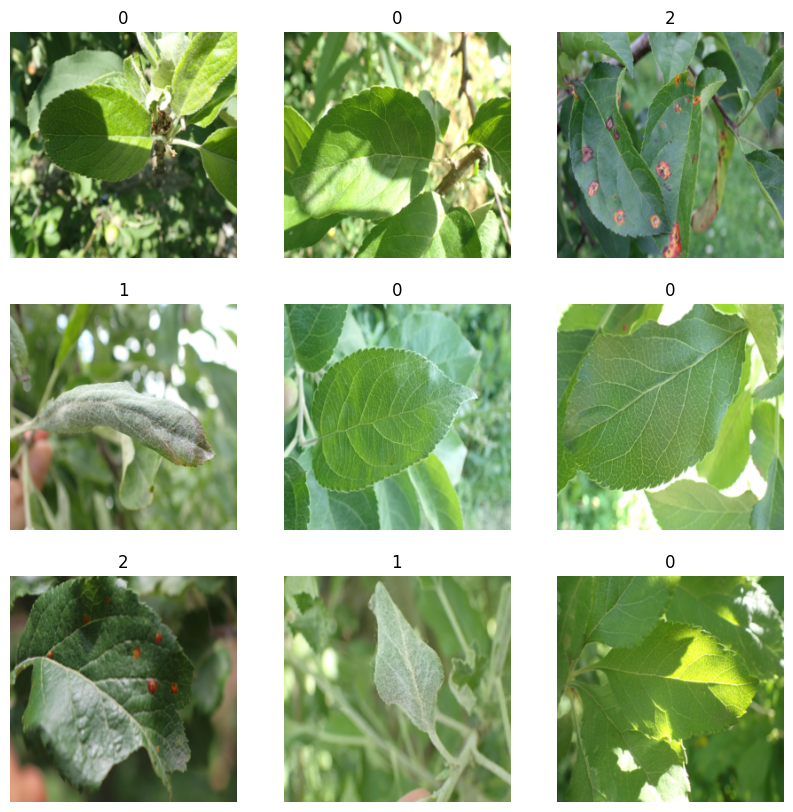

In [11]:
'''
permute reorders dimensions (no data mixing).
numpy.reshape reinterprets memory without moving anything — the data becomes scrambled and hence gray 
scaled images with 3x3 tiles.'''
fig = plt.figure(figsize=(10,10))
cols, rows = 3, 3
for i in range(9):
    sample_idx = torch.randint(len(train_data), size=(1,)).item()
    img, label = train_data[sample_idx]
    img = img.permute(1, 2, 0).numpy()
#     print(img)
#     img = np.array(img).reshape((256,256,3))
    plt.subplot(3,3,i+1)
    plt.imshow((255*img).astype("uint8"))
    plt.title(label)
    plt.axis("off")
# print(255*img)
plt.show()
fig.clear()

Implementing the CNN architecture using pytorch

In [12]:
class CNN(nn.Module):
    def __init__(self, in_channels, num_classes):

        """
        Building blocks of convolutional neural network.

        Parameters:
           * in_channels: Number of channels in the input image (for grayscale images, 1)
           * num_classes: Number of classes to predict. In our problem, 10 (i.e digits from  0 to 9).
        """
        super(CNN, self).__init__()

        # 1st convolutional layer
        self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=16, kernel_size=3, padding='same')
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, padding='same')
        # Max pooling layer
        self.pool = nn.MaxPool2d(kernel_size=2, stride=None)
        # 2nd convolutional layer
        self.conv3 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding='same')
        self.conv4 = nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding='same')
        
        with torch.no_grad():
            dummy = torch.zeros(1, in_channels, 256, 256)   # your input size
            out = self._forward_features(dummy)
            flat_dim = out.numel()

        # Fully connected layer
        self.fc1 = nn.Linear(flat_dim, num_classes)
#         self.fc2 = nn.Linear(512,128)
#         self.fc3 = nn.Linear(128,num_classes)
        

    def _forward_features(self, x):
        """
        Define the forward pass of the neural network.

        Parameters:
           x: Input tensor.

        Returns:
           torch.Tensor
               The output tensor after passing through the network.
        """
        x = F.relu(self.conv1(x))  # Apply first convolution and ReLU activation
        x = self.pool(x)           # Apply max pooling
        x = F.relu(self.conv2(x))  # Apply second convolution and ReLU activation
        x = self.pool(x)           # Apply max pooling
        x = F.dropout(x, p=0.2, training=self.training) 
        x = F.relu(self.conv3(x))  # Apply first convolution and ReLU activation
        x = self.pool(x)           # Apply max pooling
        x = F.relu(self.conv4(x))  # Apply second convolution and ReLU activation
        x = self.pool(x)
        x = F.dropout(x, p=0.2, training=self.training)  
        return x
    
    def forward(self,x):
        x = self._forward_features(x)
#         x = x.reshape(x.shape[0], -1)  # Flatten the tensor
        x = torch.flatten(x,1)
#         print(x.shape)
        x = self.fc1(x)            # Apply fully connected layer
#         x = F.dropout(x, p=0.4, training=self.training) 
#         x = self.fc2(x)
#         x = self.fc3(x)
        return x

Checking if the model has been implemented correctly.

In [13]:
model = CNN(in_channels=3, num_classes=3)
print(model)

CNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (conv4): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (fc1): Linear(in_features=8192, out_features=3, bias=True)
)


summary requires the dimension for batch as well

In [14]:
from torchinfo import summary
summary(model, (32,3,256,256))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [32, 3]                   --
├─Conv2d: 1-1                            [32, 16, 256, 256]        448
├─MaxPool2d: 1-2                         [32, 16, 128, 128]        --
├─Conv2d: 1-3                            [32, 16, 128, 128]        2,320
├─MaxPool2d: 1-4                         [32, 16, 64, 64]          --
├─Conv2d: 1-5                            [32, 32, 64, 64]          4,640
├─MaxPool2d: 1-6                         [32, 32, 32, 32]          --
├─Conv2d: 1-7                            [32, 32, 32, 32]          9,248
├─MaxPool2d: 1-8                         [32, 32, 16, 16]          --
├─Linear: 1-9                            [32, 3]                   24,579
Total params: 41,235
Trainable params: 41,235
Non-trainable params: 0
Total mult-adds (G): 3.07
Input size (MB): 25.17
Forward/backward pass size (MB): 377.49
Params size (MB): 0.16
Estimated Total Size (MB): 40

#### making an helper function to see if I can replicate the model_summary thing so that it can be used in later projects

In [15]:
def forward_with_shape_printing(model, x):
    print(f"Input shape: \t\t{x.shape}") # Using tabs for alignment
    
    x = model.conv1(x)  # Apply first convolution
    print(f"After conv_block1: \t{x.shape}")
    x = model.pool(x)   # Apply max pooling
    print(f"After max pool: \t{x.shape}")
    x = model.conv2(x)  # Apply second convolution
    print(f"After conv_block1: \t{x.shape}")
    x = model.pool(x)   # Apply max pooling
    print(f"After max pool: \t{x.shape}")
    x = model.conv3(x)  # Apply third convolution 
    print(f"After conv_block1: \t{x.shape}")
    x = model.pool(x)   # Apply max pooling
    print(f"After max pool: \t{x.shape}")
    x = model.conv4(x)  # Apply fourth convolution
    print(f"After conv_block1: \t{x.shape}")
    x = model.pool(x)   # Apply max pooling
    print(f"After max pool: \t{x.shape}")

    # Flatten the features
    x = torch.flatten(x,1)
    print(f"After flatten: \t\t{x.shape}")

    # Pass through fully connected layers (only showing final output shape)
#     x = F.relu(model.fc1(x))
#     x = model.dropout1(x)
#     x = F.relu(model.fc2(x))
#     x = model.dropout2(x)
    logits = model.fc1(x)
    print(f"Output shape (logits): \t{logits.shape}") # Corrected variable name
    
    return logits

In [16]:
dummy_input = torch.randn(32, 3, 256, 256)
print("Running shape verification pass:")
_ = forward_with_shape_printing(model, dummy_input)

Running shape verification pass:
Input shape: 		torch.Size([32, 3, 256, 256])
After conv_block1: 	torch.Size([32, 16, 256, 256])
After max pool: 	torch.Size([32, 16, 128, 128])
After conv_block1: 	torch.Size([32, 16, 128, 128])
After max pool: 	torch.Size([32, 16, 64, 64])
After conv_block1: 	torch.Size([32, 32, 64, 64])
After max pool: 	torch.Size([32, 32, 32, 32])
After conv_block1: 	torch.Size([32, 32, 32, 32])
After max pool: 	torch.Size([32, 32, 16, 16])
After flatten: 		torch.Size([32, 8192])
Output shape (logits): 	torch.Size([32, 3])


Function for training the CNN model

In [18]:
def train_model(model, train_loader, val_loader, criterion, optimizer,model_name, num_epochs=10):
    print(f'Starting training the {model_name}.pt.......')
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    model = model.to(device)
    
    train_accuracy = []
    train_loss = []
    validation_accuracy = []
    validation_loss = []
    num_epochs = num_epochs
    for epoch in range(1, num_epochs+1):
        print(f"Epoch [{epoch}/{num_epochs}]")
        running_loss = 0.0
        correct_train = 0
        total_train = 0
        for batch_index, (images, labels) in enumerate(train_loader):
#             images = images/255
#             images = images.float()
            images = images.to(device)
            labels = labels.to(device)
            model.train()
            optimizer.zero_grad()
            out = model(images)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()
#             print(out)

            # Track training loss and accuracy
            running_loss += loss.item() * images.size(0)  # loss.item() is the avg loss per batch
#             _, predicted = torch.max(out.data, 1)
#             total_train += labels.size(0)
            acc_train_batch = (out.argmax(1) == labels).float().mean()
#             print(acc_train_batch.item())
            correct_train += acc_train_batch.item()

        epoch_train_loss = running_loss / len(train_loader.dataset)
#         print(f'{correct_train=}')
#         print(f'{len(train_loader)}')
        epoch_train_acc = correct_train / len(train_loader)
        train_loss.append(epoch_train_loss)
        train_accuracy.append(epoch_train_acc)

        model.eval()  # Set model to evaluation mode (disables dropout, uses running stats for batch norm)
        val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for batch, (images, labels) in enumerate(val_loader):
#                 images = images/255
#                 images = images.float()
                images = images.to(device)
                labels = labels.to(device)
                out = model(images)
                loss = criterion(out, labels)

                val_loss += loss.item() * images.size(0)
#                 _, predicted = torch.max(out.data, 1)
#                 total_val += labels.size(0)
                acc_val_batch = (out.argmax(1) == labels).float().mean()
#                 print(acc_val_batch.item())
                correct_val += acc_val_batch.item()

            # Calculate validation statistics for the epoch
        epoch_val_loss = val_loss / len(val_loader.dataset)
#         print(f'{correct_val=}')
#         print(f'{len(val_loader)}')
        epoch_val_acc = correct_val/ len(val_loader)              
        validation_loss.append(epoch_val_loss)                    
        validation_accuracy.append(epoch_val_acc) 


        print(f"  Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f}")
        print(f"  Validation Loss: {epoch_val_loss:.4f}, Validation Acc: {epoch_val_acc:.4f}")
        print('-'*30)
        
    print("Finished Training.....")
    print('Saving model and the training accuracies....')
    torch.save(model, f'{model_name}.pt')
    training_details = {'train_losses': train_loss, 'train_accuracies': train_accuracy, 
                        'val_losses': validation_loss, 'val_accuracies': validation_accuracy}
    torch.save(training_details, f'train_val_accuracy_data.pt')
    return training_details

In [19]:
model_new = CNN(in_channels=3, num_classes=3)
print(model_new)
optimizer = torch.optim.Adam(model_new.parameters(), lr=0.0001, weight_decay=5e-4)
criterion = torch.nn.CrossEntropyLoss()
train_model(model_new, val_dl, val_dl, criterion, optimizer,'recognize_disease_test')

CNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (conv4): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (fc1): Linear(in_features=8192, out_features=3, bias=True)
)
Starting training the recognize_disease_test.pt.......
Using device: cpu
Epoch [1/10]
  Train Loss: 1.0986, Train Acc: 0.2969
  Validation Loss: 1.0982, Validation Acc: 0.3326
------------------------------
Epoch [2/10]
  Train Loss: 1.0968, Train Acc: 0.3772
  Validation Loss: 1.0979, Validation Acc: 0.3504
------------------------------
Epoch [3/10]
  Train Loss: 1.0932, Train Acc: 0.4375
  Validation Loss: 1.0975, Validation Acc: 0.4397
------------------------------
Epoch [4/10]
  Train Loss: 1.0956, Train Acc: 0.3638
  Validation Loss: 1

{'train_losses': [1.0985655625661215,
  1.0967624187469482,
  1.0932157119115193,
  1.0956453720728556,
  1.0934552987416586,
  1.0950676520665488,
  1.087253244717916,
  1.0909079631169638,
  1.0934860785802205,
  1.0891133864720663],
 'train_accuracies': [0.296875,
  0.3772321492433548,
  0.4375,
  0.3638392835855484,
  0.4017857164144516,
  0.3928571492433548,
  0.34375,
  0.3861607164144516,
  0.3660714328289032,
  0.3683035671710968],
 'val_losses': [1.0982245445251464,
  1.097937035560608,
  1.0974775393803915,
  1.0969869057337442,
  1.0964980522791545,
  1.0958839178085327,
  1.0952467997868855,
  1.0944915056228637,
  1.0935867230097454,
  1.0925628344217937],
 'val_accuracies': [0.3325892835855484,
  0.3504464328289032,
  0.4397321343421936,
  0.4040178507566452,
  0.4308035671710968,
  0.3816964328289032,
  0.328125,
  0.4040178507566452,
  0.4665178507566452,
  0.5178571343421936]}

### Training the model using GPU for more epochs. Lets see the performance of the model

In [38]:
model = torch.load('recognize_disease_27_07_more_epochs.pt', weights_only=False, map_location=torch.device('cpu'))
training_details = torch.load('train_val_accuracy_data.pt')

In [39]:
from torchinfo import summary
print('Model details\n')
print(model)
print('\nSummary of the architecture\n')
print(summary(model, (32,3,256,256)))

Model details

CNN(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (conv2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (conv4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (fc1): Linear(in_features=65536, out_features=3, bias=True)
)

Summary of the architecture

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [32, 3]                   --
├─Conv2d: 1-1                            [32, 64, 256, 256]        1,792
├─MaxPool2d: 1-2                         [32, 64, 128, 128]        --
├─Conv2d: 1-3                            [32, 128, 128, 128]       73,856
├─MaxPool2d: 1-4                         [32, 128, 64, 64]         --
├─Conv2d: 1-5                            [32, 256, 64, 64]       

In [40]:
# print(training_details)
train_losses = training_details['train_losses']
val_losses = training_details['val_losses']
train_accuracies = training_details['train_accuracies']
val_accuracies = training_details['val_accuracies']
print(len(train_accuracies))

35


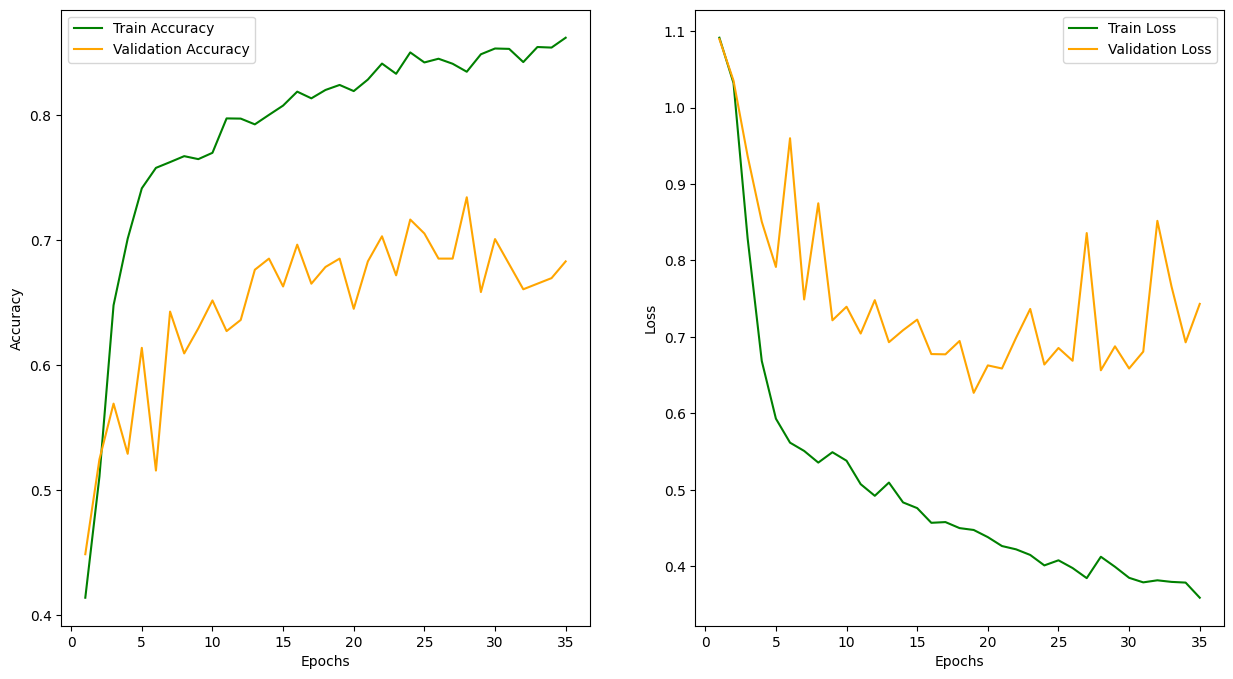

In [41]:
num_epochs = range(1,len(train_accuracies)+1)
fig, axs = plt.subplots(1,2)
# print(axs)
axs[0].plot(num_epochs, train_accuracies,color='g', label='Train Accuracy')
axs[0].plot(num_epochs, val_accuracies, color='orange', label='Validation Accuracy')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Accuracy')
axs[0].legend()
axs[1].plot(num_epochs, train_losses,color='g', label='Train Loss')
axs[1].plot(num_epochs, val_losses, color='orange', label='Validation Loss')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Loss')
axs[1].legend()
fig.set_size_inches((15,8))
plt.show()

In [42]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, weight_decay=5e-4)
criterion = torch.nn.CrossEntropyLoss()
model.eval()  # Set model to evaluation mode (disables dropout, uses running stats for batch norm)
val_loss = 0.0
correct_val = 0
total_val = 0

with torch.no_grad():
    for batch, (images, labels) in enumerate(val_dl): 
        out = model(images)
        loss = criterion(out, labels)

        val_loss += loss.item() * images.size(0)
        acc_val_batch = (out.argmax(1) == labels).float().mean()
#                 print(acc_val_batch.item())
        correct_val += acc_val_batch.item()

            # Calculate validation statistics for the epoch
epoch_val_loss = val_loss / len(val_dl.dataset)
#         print(f'{correct_val=}')
#         print(f'{len(val_loader)}')
epoch_val_acc = correct_val/ len(val_dl)  

In [43]:
print('Accuracy and loss on Validation set (not so meaningful as it was trained on that)')
print('Accuracy: ', epoch_val_acc)
print('Loss:', epoch_val_loss)

Accuracy and loss on Validation set (not so meaningful as it was trained on that)
Accuracy:  0.8995535671710968
Loss: 0.31587789158026375


In [33]:
model.eval()  # Set model to evaluation mode (disables dropout, uses running stats for batch norm)
test_loss = 0.0
correct_test = 0
total_test = 0

with torch.no_grad():
    for batch, (images, labels) in enumerate(test_dl): 
        out = model(images)
        loss = criterion(out, labels)

        test_loss += loss.item() * images.size(0)
        acc_test_batch = (out.argmax(1) == labels).float().mean()
#                 print(acc_val_batch.item())
        correct_test += acc_test_batch.item()

            # Calculate validation statistics for the epoch
epoch_test_loss = test_loss / len(test_dl.dataset)
#         print(f'{correct_val=}')
#         print(f'{len(val_loader)}')
epoch_test_acc = correct_test/ len(test_dl)  

In [34]:
print('Accuracy and loss on Test set')
print('Accuracy: ', epoch_test_acc)
print('Loss:', epoch_test_loss)

Accuracy and loss on Test set
Accuracy:  0.9096590876579285
Loss: 0.4915047510464986


### Lets see the performance of the model with more complex layers trained on GPUs: especially the following structure

In [44]:
model = torch.load('recognize_disease_27_07_more_complex.pt', weights_only=False, map_location=torch.device('cpu'))
training_details = torch.load('train_val_accuracy_data_more_layers.pt')

from torchinfo import summary
print('Model details\n')
print(model)
print('\nSummary of the architecture\n')
print(summary(model, (32,3,256,256)))

Model details

CNN(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (conv2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (conv4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (fc1): Linear(in_features=65536, out_features=3, bias=True)
)

Summary of the architecture

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [32, 3]                   --
├─Conv2d: 1-1                            [32, 64, 256, 256]        1,792
├─MaxPool2d: 1-2                         [32, 64, 128, 128]        --
├─Conv2d: 1-3                            [32, 128, 128, 128]       73,856
├─MaxPool2d: 1-4                         [32, 128, 64, 64]         --
├─Conv2d: 1-5                            [32, 256, 64, 64]       

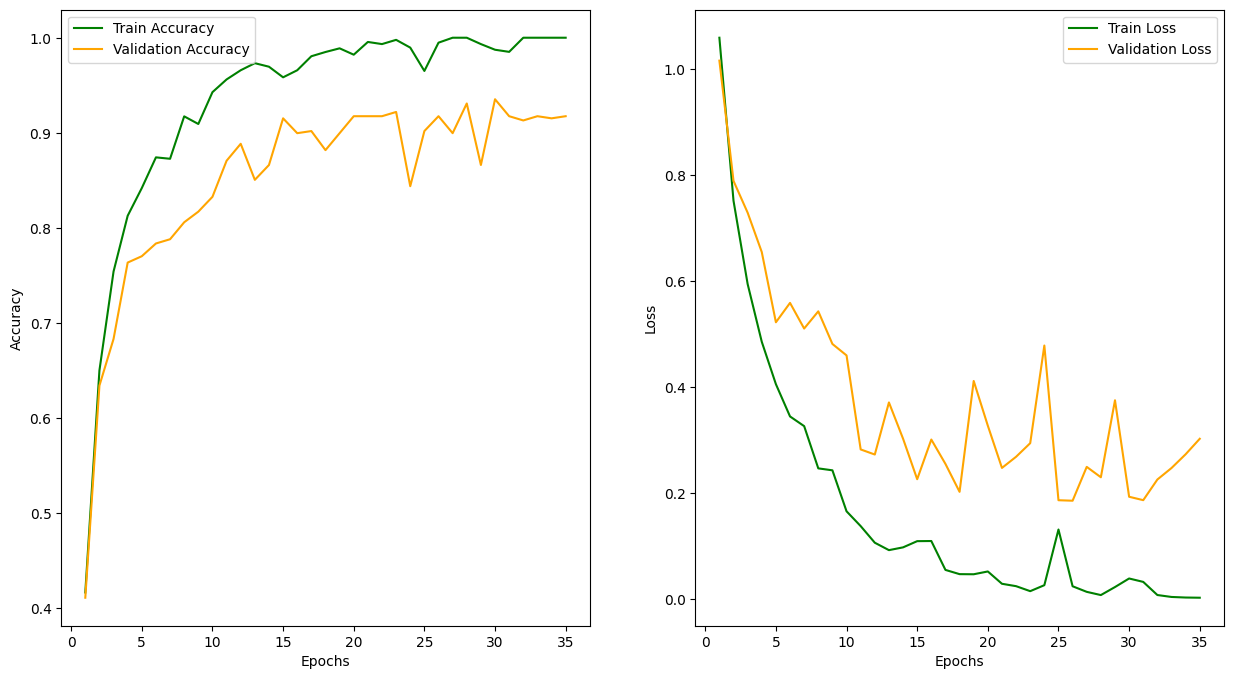

In [45]:
train_losses = training_details['train_losses']
val_losses = training_details['val_losses']
train_accuracies = training_details['train_accuracies']
val_accuracies = training_details['val_accuracies']

num_epochs = range(1,len(train_accuracies)+1)
fig, axs = plt.subplots(1,2)
# print(axs)
axs[0].plot(num_epochs, train_accuracies,color='g', label='Train Accuracy')
axs[0].plot(num_epochs, val_accuracies, color='orange', label='Validation Accuracy')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Accuracy')
axs[0].legend()
axs[1].plot(num_epochs, train_losses,color='g', label='Train Loss')
axs[1].plot(num_epochs, val_losses, color='orange', label='Validation Loss')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Loss')
axs[1].legend()
fig.set_size_inches((15,8))
plt.show()

In [46]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, weight_decay=5e-4)
criterion = torch.nn.CrossEntropyLoss()
model.eval()  # Set model to evaluation mode (disables dropout, uses running stats for batch norm)
val_loss = 0.0
correct_val = 0
total_val = 0

with torch.no_grad():
    for batch, (images, labels) in enumerate(val_dl): 
        out = model(images)
        loss = criterion(out, labels)

        val_loss += loss.item() * images.size(0)
        acc_val_batch = (out.argmax(1) == labels).float().mean()
#                 print(acc_val_batch.item())
        correct_val += acc_val_batch.item()

            # Calculate validation statistics for the epoch
epoch_val_loss = val_loss / len(val_dl.dataset)
#         print(f'{correct_val=}')
#         print(f'{len(val_loader)}')
epoch_val_acc = correct_val/ len(val_dl)  

print('Accuracy and loss on Validation set (not so meaningful as it was trained on that)')
print('Accuracy: ', epoch_val_acc)
print('Loss:', epoch_val_loss)

# model.eval()  # Set model to evaluation mode (disables dropout, uses running stats for batch norm)
test_loss = 0.0
correct_test = 0
total_test = 0

with torch.no_grad():
    for batch, (images, labels) in enumerate(test_dl): 
        out = model(images)
        loss = criterion(out, labels)

        test_loss += loss.item() * images.size(0)
        acc_test_batch = (out.argmax(1) == labels).float().mean()
#                 print(acc_val_batch.item())
        correct_test += acc_test_batch.item()

            # Calculate validation statistics for the epoch
epoch_test_loss = test_loss / len(test_dl.dataset)
#         print(f'{correct_val=}')
#         print(f'{len(val_loader)}')
epoch_test_acc = correct_test/ len(test_dl)  

print('Accuracy and loss on Test set')
print('Accuracy: ', epoch_test_acc)
print('Loss:', epoch_test_loss)

Accuracy and loss on Validation set (not so meaningful as it was trained on that)
Accuracy:  0.921875
Loss: 0.3022603034973145
Accuracy and loss on Test set
Accuracy:  0.9068181872367859
Loss: 0.4565617026885351
